<a href="https://colab.research.google.com/github/JohnW0728/nlp-news-topic-classifier/blob/main/NLP_Project_Group_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WID3002 Natural Language Processing Group Project
# **Document Topic Classifier** by Group 13

**Group Members**
1. Tan Yi Jing (24004568)
2. Valencien Seow Yun Sun (24004618)
3. Kan Penny (24004556)
4. Sanjeevan Kumareson (23109697)
5. John Wong Sie Wei (24066701)
6. Lee Jing Xuan (22098489)

# Section 0 — Setup & Installs

This notebook installs all required libraries for the project:
- **transformers** - Hugging Face library for RoBERTa
- **scikit-learn** - TF-IDF baseline, metrics, label encoding
- **streamlit / pyngrok** - live demo interface

In [ ]:
# Install all dependencies
!pip install transformers datasets sentence-transformers \
             streamlit PyPDF2 pyngrok scikit-learn -q

print("All installed!")

All installed!


# Section 1 — Data Loading & EDA

We load the **HuffPost News Category Dataset v3** (~200k articles) from Google Drive. Each row contains a `headline`, `short_description`, and `category`. We combine `headline + short_description` as the input text for classification.

In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt

# 1. Mount the shared Drive
drive.mount('/content/drive')

# 2. Load the JSON directly from the shared Drive folder
file_path = '/content/drive/MyDrive/NLP_Group13/data/raw/News_Category_Dataset_v3.json'

df = pd.read_json(file_path, lines=True)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst row:")
print(df.iloc[0])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (209527, 6)
Columns: ['link', 'headline', 'category', 'short_description', 'authors', 'date']

First row:
link                 https://www.huffpost.com/entry/covid-boosters-...
headline             Over 4 Million Americans Roll Up Sleeves For O...
category                                                     U.S. NEWS
short_description    Health experts said it is too early to predict...
authors                                           Carla K. Johnson, AP
date                                               2022-09-23 00:00:00
Name: 0, dtype: object


The raw dataset has **42 categories**, many of which are overlapping or redundant (e.g. `WORLDPOST` and `THE WORLDPOST`, `STYLE` and `STYLE & BEAUTY`). We first inspect the full distribution before merging.

In [ ]:
# Before merging — see all raw categories
print("Total unique categories:", df['category'].nunique())
print("\nFull distribution:")
print(df['category'].value_counts())

Total unique categories: 42

Full distribution:
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO 

The bar chart visualises the **top 15 most common raw categories**. Notice the heavy imbalance - `POLITICS` alone has over 35,000 articles while smaller categories have under 1,000. This imbalance motivates both merging and balancing.

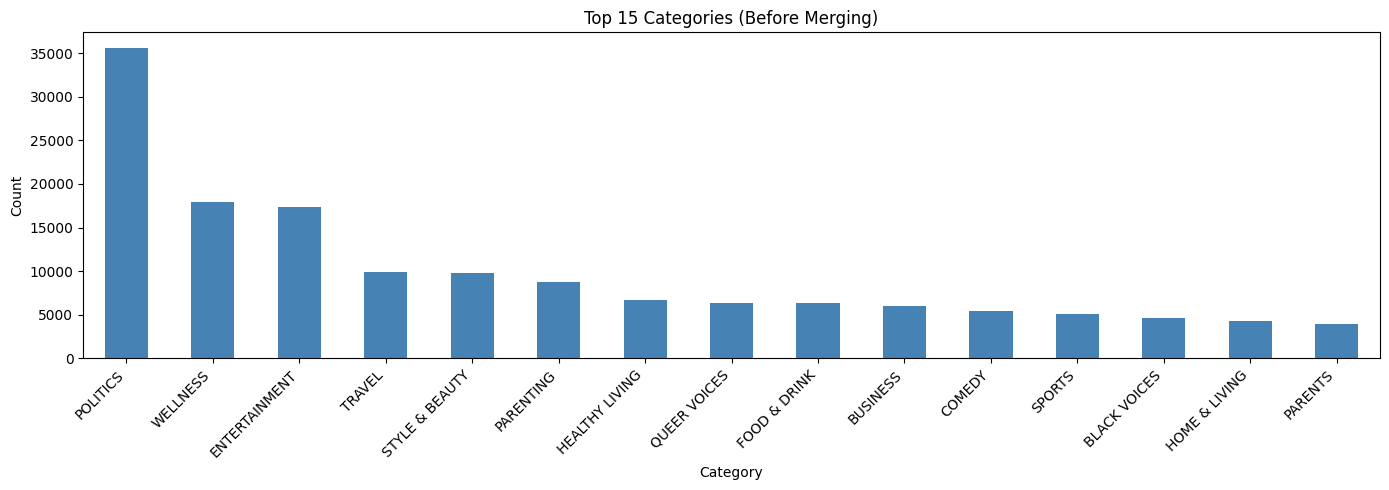

In [ ]:
# Plot top 15 before merging
df['category'].value_counts().head(15).plot(
    kind='bar', color='steelblue', figsize=(14, 5))
plt.title('Top 15 Categories (Before Merging)')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Section 2 — Preprocessing

**Category Merging** - We reduce 42 raw categories down to **18 clean categories** by:
- Merging near-identical labels (e.g. `WORLDPOST` + `THE WORLDPOST` → `WORLD NEWS`)
- Dropping 6 ambiguous categories (`BLACK VOICES`, `LATINO VOICES`, etc.) that overlap heavily with others and hurt model accuracy
- Moving `U.S. NEWS` → `POLITICS` since the content is politically adjacent

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

category_mapping = {
    # POLITICS
    'POLITICS':         'POLITICS',
    'U.S. NEWS':        'POLITICS',

    # ENTERTAINMENT
    'ENTERTAINMENT':    'ENTERTAINMENT',
    'COMEDY':           'ENTERTAINMENT',
    'ARTS':             'ENTERTAINMENT',
    'ARTS & CULTURE':   'ENTERTAINMENT',
    'CULTURE & ARTS':   'ENTERTAINMENT',

    # WELLNESS
    'WELLNESS':         'WELLNESS',
    'HEALTHY LIVING':   'WELLNESS',

    # LIFESTYLE
    'LIFESTYLE':        'LIFESTYLE',
    'HOME & LIVING':    'LIFESTYLE',
    'WEDDINGS':         'LIFESTYLE',
    'DIVORCE':          'LIFESTYLE',
    'FIFTY':            'LIFESTYLE',

    # TRAVEL
    'TRAVEL':           'TRAVEL',

    # STYLE & BEAUTY
    'STYLE & BEAUTY':   'STYLE & BEAUTY',
    'STYLE':            'STYLE & BEAUTY',

    # PARENTING
    'PARENTING':        'PARENTING',
    'PARENTS':          'PARENTING',

    # FOOD & DRINK
    'FOOD & DRINK':     'FOOD & DRINK',
    'TASTE':            'FOOD & DRINK',

    # BUSINESS
    'BUSINESS':         'BUSINESS',
    'MONEY':            'BUSINESS',

    # SPORTS
    'SPORTS':           'SPORTS',

    # CRIME
    'CRIME':            'CRIME',

    # WORLD NEWS
    'WORLD NEWS':       'WORLD NEWS',
    'WORLDPOST':        'WORLD NEWS',
    'THE WORLDPOST':    'WORLD NEWS',
    'WEIRD NEWS':       'WORLD NEWS',
    'GOOD NEWS':        'WORLD NEWS',

    # TECH
    'TECH':             'TECHNOLOGY',

    # SCIENCE
    'SCIENCE':          'SCIENCE',

    # RELIGION
    'RELIGION':         'RELIGION',

    # MEDIA
    'MEDIA':            'MEDIA',

    # EDUCATION
    'EDUCATION':        'EDUCATION',

    # ENVIRONMENT
    'ENVIRONMENT':      'ENVIRONMENT',
    'GREEN':            'ENVIRONMENT',
}

# Just drop rows with these categories before mapping
drop_categories = [
    'BLACK VOICES',    # U.S. racial politics
    'LATINO VOICES',   # U.S. specific
    'QUEER VOICES',    # sensitive, U.S. context
    'WOMEN',           # too broad/ambiguous
    'IMPACT',          # vague
    'COLLEGE',         # U.S. college culture
]

df = df[~df['category'].isin(drop_categories)]
df['category'] = df['category'].replace(category_mapping)

print(f"After merging: {df['category'].nunique()} categories")
print(df['category'].value_counts())

After merging: 18 categories
category
POLITICS          36979
ENTERTAINMENT     26684
WELLNESS          24639
WORLD NEWS        13717
LIFESTYLE         12800
PARENTING         12746
STYLE & BEAUTY    12068
TRAVEL             9900
FOOD & DRINK       8436
BUSINESS           7748
SPORTS             5077
ENVIRONMENT        4066
CRIME              3562
MEDIA              2944
RELIGION           2577
SCIENCE            2206
TECHNOLOGY         2104
EDUCATION          1014
Name: count, dtype: int64


After merging, we have **18 clearly-defined categories**. The distribution is more uniform, and semantically similar labels have been consolidated. This reduces confusion during training.

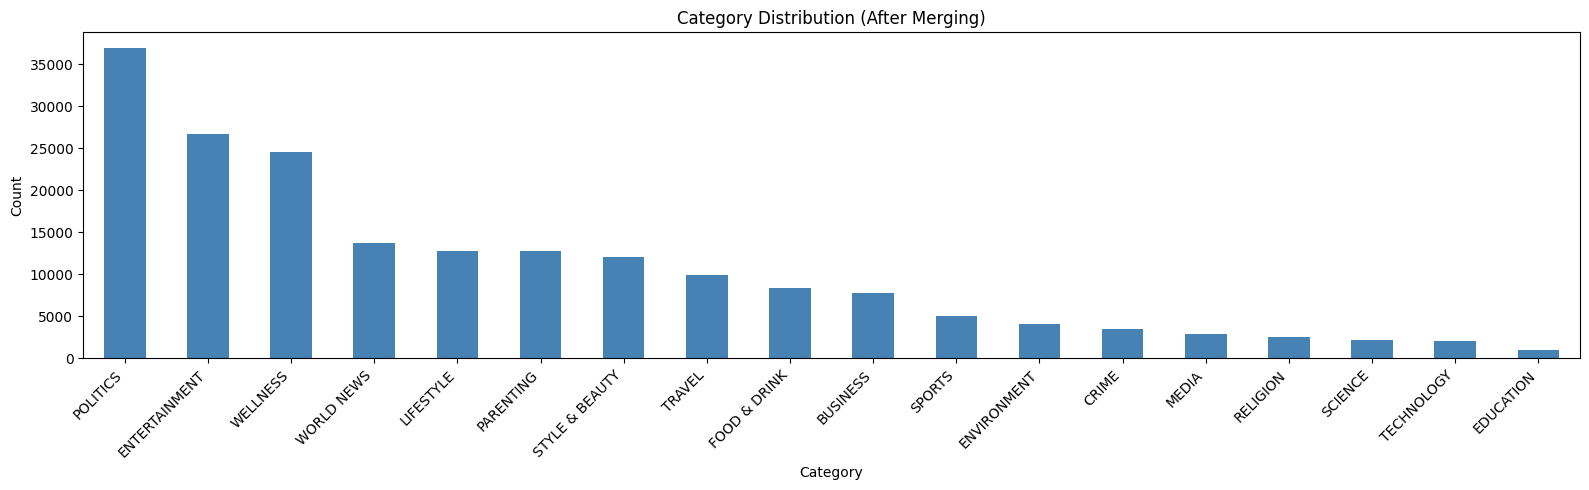

In [ ]:
# Plot after merging
df['category'].value_counts().plot(
    kind='bar', color='steelblue', figsize=(16, 5))
plt.title('Category Distribution (After Merging)')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Balancing** - We cap each category at **1,000 samples** to prevent the model from being biased towards larger classes. After deduplication and empty row removal, the dataset is clean and evenly distributed.




In [ ]:
# Balance
df_balanced = df.groupby('category', group_keys=False).apply(
    lambda x: x.sample(min(len(x), 1000), random_state=42)
).reset_index(drop=True)

# Combine headline + description
df_balanced['text'] = df_balanced['headline'] + ' ' + df_balanced['short_description']

# Remove duplicates and empty rows
df_balanced = df_balanced.drop_duplicates(subset=['text'])
df_balanced = df_balanced[df_balanced['text'].str.strip() != '']
df_balanced = df_balanced.reset_index(drop=True)

print(f"Total rows: {len(df_balanced)}")
print(f"Total categories: {df_balanced['category'].nunique()}\n")
print(df_balanced['category'].value_counts())

Total rows: 17972
Total categories: 18

category
CRIME             1000
EDUCATION         1000
WORLD NEWS        1000
ENTERTAINMENT     1000
ENVIRONMENT       1000
FOOD & DRINK      1000
LIFESTYLE         1000
MEDIA             1000
POLITICS          1000
SCIENCE           1000
WELLNESS          1000
SPORTS            1000
TRAVEL            1000
BUSINESS           999
PARENTING          999
STYLE & BEAUTY     999
RELIGION           997
TECHNOLOGY         978
Name: count, dtype: int64


/tmp/ipykernel_507/2079186509.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby('category', group_keys=False).apply(


After capping at 1,000 samples per category, the dataset is **fully balanced**. Each class contributes equally to training, preventing the model from defaulting to majority classes.

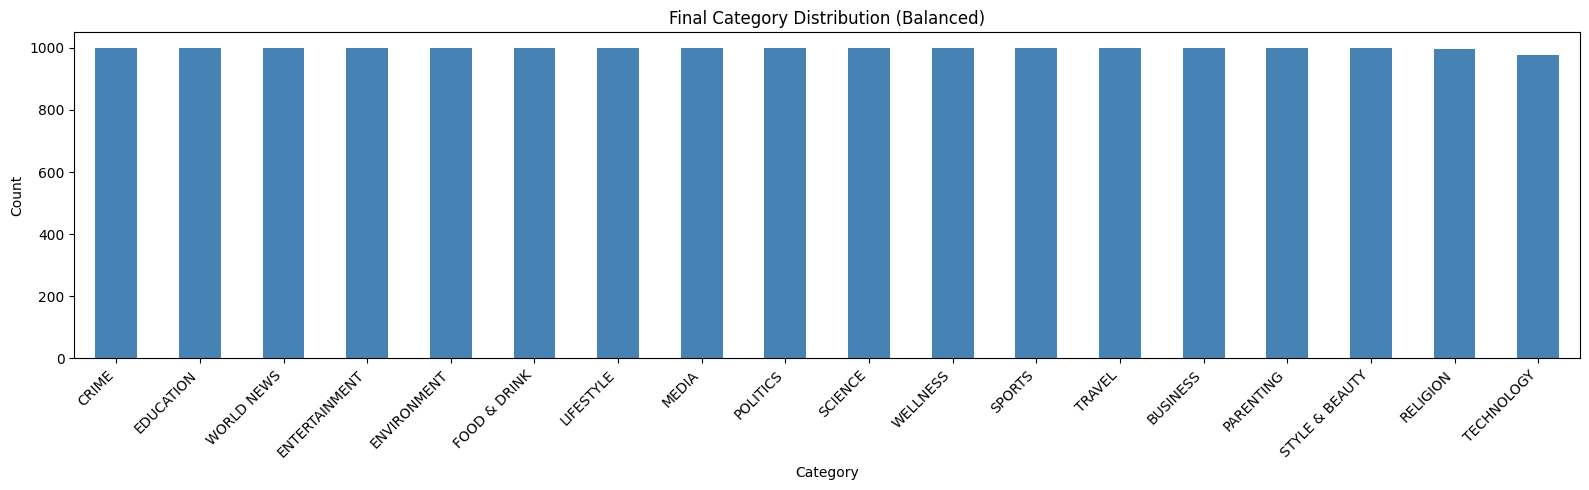

In [ ]:
# Plot final balanced distribution
df_balanced['category'].value_counts().plot(
    kind='bar', color='steelblue', figsize=(16, 5))
plt.title('Final Category Distribution (Balanced)')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Text Cleaning** is done here. We apply a *light* cleaning pipeline intentionally:
- Strip HTML tags only
- Normalise whitespace

We purposely **do not** lowercase or strip punctuation - RoBERTa was pretrained on natural text and performs better when punctuation is preserved.

In [ ]:
import re

# Clean text - strip HTML and normalise whitespace
def clean_text(text):
    text = str(text)
    text = re.sub(r'<.*?>', '', text)           # strip HTML tags only
    text = re.sub(r'\s+', ' ', text).strip()    # normalise whitespace
    return text

df_balanced['clean_text'] = df_balanced['text'].apply(clean_text)

print("Cleaning done!")
print("\nSample cleaned text:")
print(df_balanced['clean_text'].iloc[0])

Cleaning done!

Sample cleaned text:
Microsoft Just Took A Step Toward Actual Gender Diversity Soon three women will serve on Microsoft's board -- meeting the real threshold for gender diversity.


**Label Encoding** - Category names are converted to integer indices using `LabelEncoder`. The encoder is saved to Drive so the Streamlit app can decode predictions back to category names.

In [ ]:
# Encode labels
le = LabelEncoder()
df_balanced['label'] = le.fit_transform(df_balanced['category'])

num_labels = len(le.classes_)
print(f"Total classes: {num_labels}")
print("\nLabel mapping:")
for i, cls in enumerate(le.classes_):
    print(f"  {i:2d} → {cls}")

Total classes: 18

Label mapping:
   0 → BUSINESS
   1 → CRIME
   2 → EDUCATION
   3 → ENTERTAINMENT
   4 → ENVIRONMENT
   5 → FOOD & DRINK
   6 → LIFESTYLE
   7 → MEDIA
   8 → PARENTING
   9 → POLITICS
  10 → RELIGION
  11 → SCIENCE
  12 → SPORTS
  13 → STYLE & BEAUTY
  14 → TECHNOLOGY
  15 → TRAVEL
  16 → WELLNESS
  17 → WORLD NEWS


In [ ]:
import joblib
joblib.dump(le, '/content/drive/MyDrive/NLP_Group13/models/label_encoder.pkl')
print('LabelEncoder saved.')

LabelEncoder saved.


**Train / Validation / Test Split**
- **70%** training - used to update model weights
- **10%** validation - used during training to monitor accuracy and to trigger early stopping
- **20%** test - held out entirely, only used for final evaluation

Stratified splitting ensures each split has the same class distribution.

In [ ]:
# Train/test split 80/20
X_temp, X_test, y_temp, y_test = train_test_split(
    df_balanced['clean_text'].tolist(),
    df_balanced['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df_balanced['label']
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.125,
    random_state=42,
    stratify=y_temp
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

Train: 12579 | Val: 1798 | Test: 3595


#Section 3 — TF-IDF classifier

## Baseline: TF-IDF + Logistic Regression

Before training a deep model, we establish a **classical NLP baseline** using:
- **TF-IDF** (Term Frequency-Inverse Document Frequency) to convert text into numeric features
- **Logistic Regression** as the classifier

This gives us a reference score to compare against RoBERTa. If RoBERTa only marginally outperforms TF-IDF, the extra complexity is not justified.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os

tfidf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=100_000,
        ngram_range=(1, 2),
        sublinear_tf=True,
    )),
    ('clf', LogisticRegression(
        max_iter=1000,
        C=5.0,
        solver='lbfgs',
        multi_class='multinomial',
        random_state=42,
        n_jobs=-1,
    )),
])

print('Fitting TF-IDF pipeline...')
tfidf_pipeline.fit(X_train, y_train)
print('Training complete.')

Fitting TF-IDF pipeline...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Training complete.


**Evaluation** - We report per-class precision, recall, and F1 score. The macro-average F1 treats all classes equally regardless of size, making it a fair metric for a balanced dataset.

In [ ]:
y_pred_tfidf = tfidf_pipeline.predict(X_test)
target_names = le.classes_.tolist()

print('Classification Report — TF-IDF + Logistic Regression')
print('=' * 60)
print(classification_report(y_test, y_pred_tfidf, target_names=target_names))

tfidf_accuracy = np.mean(np.array(y_pred_tfidf) == np.array(y_test))
tfidf_macro_f1 = f1_score(y_test, y_pred_tfidf, average='macro')

print(f'Overall Accuracy : {tfidf_accuracy:.4f} ({tfidf_accuracy*100:.2f}%)')
print(f'Macro-average F1 : {tfidf_macro_f1:.4f}')

Classification Report — TF-IDF + Logistic Regression
                precision    recall  f1-score   support

      BUSINESS       0.52      0.55      0.53       200
         CRIME       0.67      0.77      0.71       200
     EDUCATION       0.80      0.73      0.77       200
 ENTERTAINMENT       0.57      0.49      0.53       200
   ENVIRONMENT       0.60      0.61      0.61       200
  FOOD & DRINK       0.79      0.75      0.77       200
     LIFESTYLE       0.65      0.63      0.64       200
         MEDIA       0.70      0.64      0.67       200
     PARENTING       0.56      0.71      0.63       200
      POLITICS       0.60      0.59      0.60       200
      RELIGION       0.78      0.60      0.68       199
       SCIENCE       0.67      0.60      0.64       200
        SPORTS       0.76      0.79      0.77       200
STYLE & BEAUTY       0.77      0.77      0.77       200
    TECHNOLOGY       0.64      0.62      0.63       196
        TRAVEL       0.63      0.69      0.66     

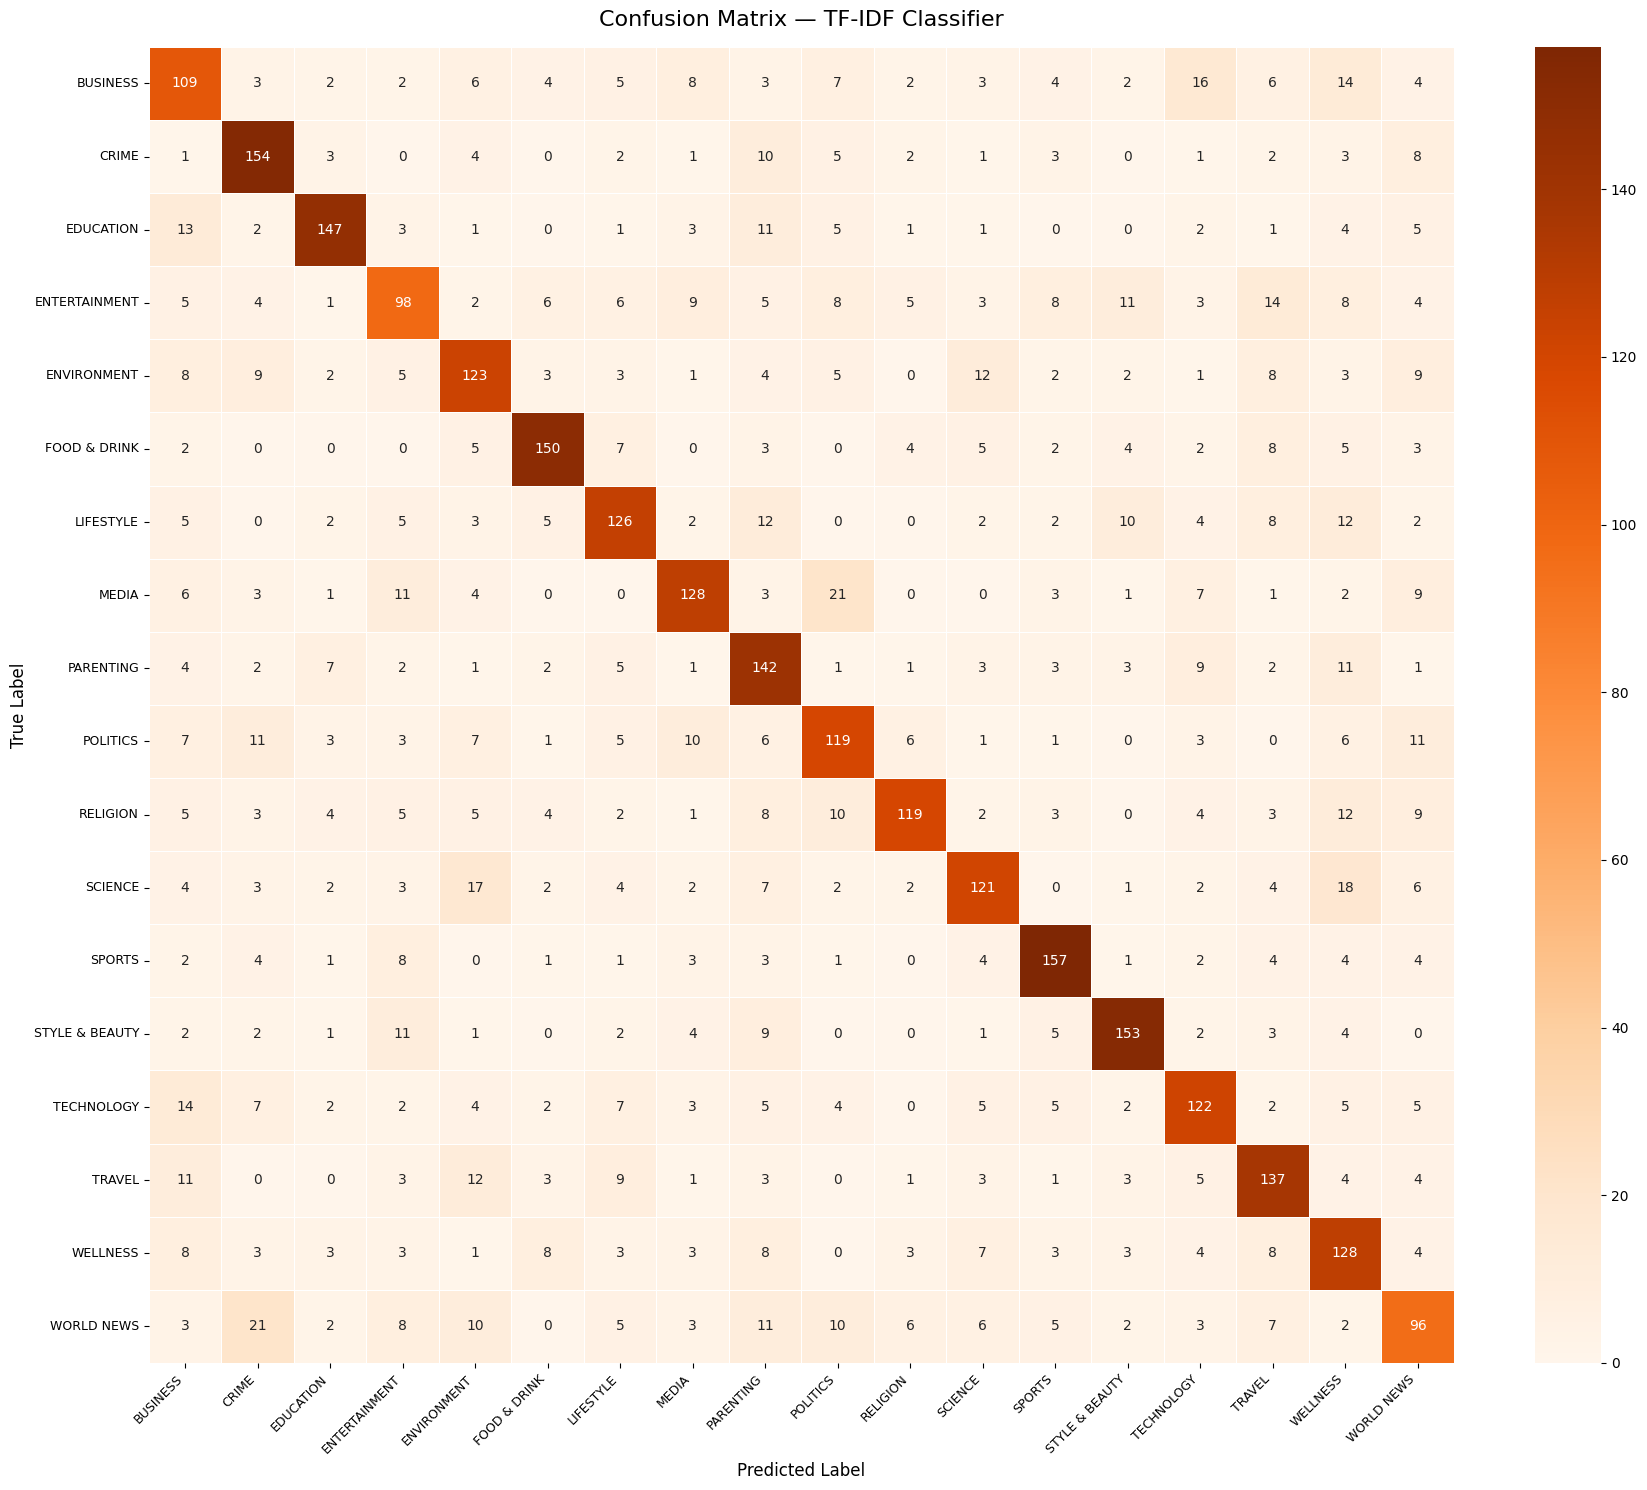

In [ ]:
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Oranges',
            xticklabels=target_names, yticklabels=target_names,
            linewidths=0.5, ax=ax)
ax.set_title('Confusion Matrix — TF-IDF Classifier', fontsize=16, pad=15)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

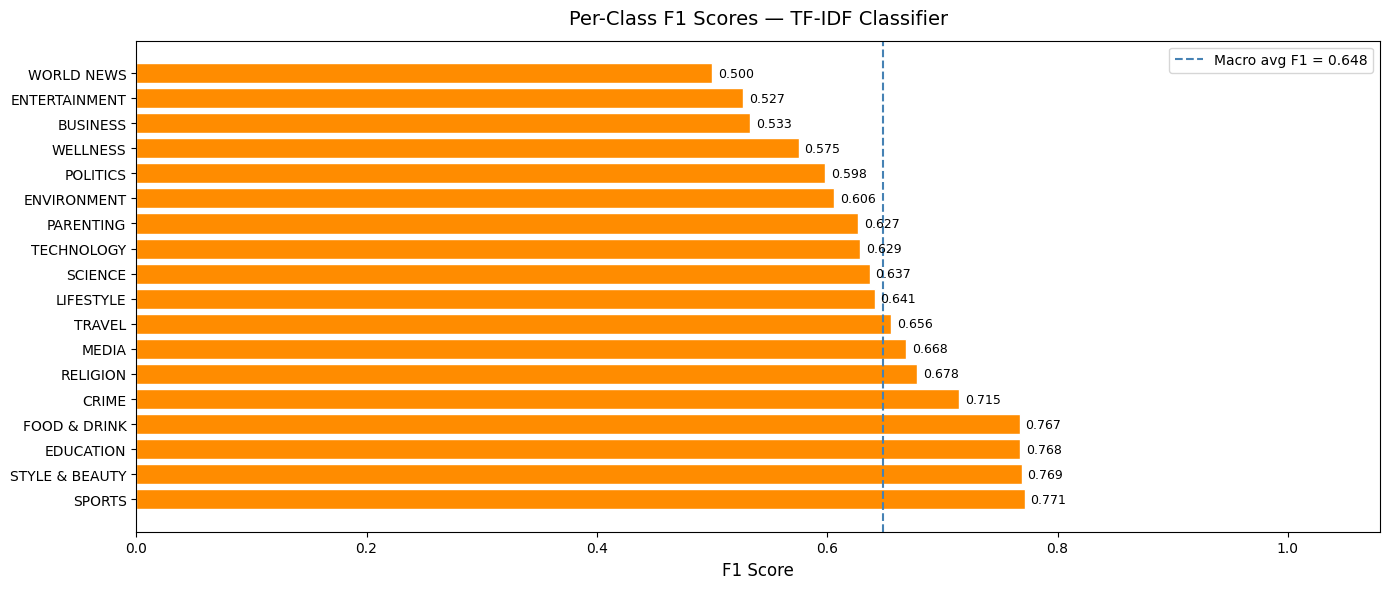

Macro-average F1: 0.6480


In [ ]:
f1_per_class = f1_score(y_test, y_pred_tfidf, average=None)
sorted_pairs = sorted(zip(f1_per_class, target_names), reverse=True)
sorted_f1, sorted_names = zip(*sorted_pairs)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.barh(sorted_names, sorted_f1, color='darkorange', edgecolor='white')

for bar, score in zip(bars, sorted_f1):
    ax.text(score + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{score:.3f}', va='center', ha='left', fontsize=9)

ax.set_xlim(0, 1.08)
ax.set_xlabel('F1 Score', fontsize=12)
ax.set_title('Per-Class F1 Scores — TF-IDF Classifier', fontsize=14, pad=12)
ax.axvline(x=np.mean(f1_per_class), color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Macro avg F1 = {np.mean(f1_per_class):.3f}')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()
print(f'Macro-average F1: {np.mean(f1_per_class):.4f}')

**`classify_tfidf()`** - Wraps the TF-IDF pipeline into a reusable function with the same output format as the RoBERTa `classify()`. Uses **entropy** over the probability distribution to detect uncertain predictions:
- **High confidence (≥ 0.60)** → Hard Label
- **Low entropy (< 2.5)** → Multi-Label (document spans two topics)
- **Otherwise** → Out-of-Distribution

In [ ]:
import re
import scipy.stats as stats

def classify_tfidf(text: str, top_k: int = 18) -> dict:
    """
    Classify a document using the TF-IDF + Logistic Regression pipeline.
    Returns the same dict format as classify() so Streamlit can use both.
    """
    # Clean text
    text_clean = re.sub(r'<.*?>', '', str(text))
    text_clean = re.sub(r'\s+', ' ', text_clean).strip()

    # Get probability scores for all classes
    probs_array = tfidf_pipeline.predict_proba([text_clean])[0]

    # Sort by confidence descending
    top_k_indices = np.argsort(probs_array)[::-1][:top_k]
    top_k_preds   = [(le.classes_[i], round(float(probs_array[i]), 4)) for i in top_k_indices]

    top_conf = top_k_preds[0][1]
    entropy  = stats.entropy([p for _, p in top_k_preds])

    # Same routing logic as RoBERTa classify()
    if top_conf >= 0.60:
        route = 'HARD LABEL'
    elif entropy < 2.5:
        route = 'MULTI-LABEL'
    else:
        route = 'OUT-OF-DISTRIBUTION'

    return {
        'predicted_label':   top_k_preds[0][0],
        'confidence':        top_conf,
        'top_k_predictions': top_k_preds,
        'entropy':           round(entropy, 4),
        'route':             route,
    }

print('classify_tfidf() ready.')

# Quick smoke test
test_result = classify_tfidf('NASA launches new rocket to the moon for lunar exploration mission.')
print(f"\nSmoke test → {test_result['predicted_label']} ({test_result['confidence']*100:.1f}%) | Route: {test_result['route']}")

classify_tfidf() ready.

Smoke test → SCIENCE (97.5%) | Route: HARD LABEL


We save the TF-IDF pipeline to Google Drive so the **Streamlit app can load it directly** without retraining. Both the vectorizer and classifier are bundled together in a single `.pkl` file via scikit-learn's `Pipeline`.

In [ ]:
tfidf_save_path = '/content/drive/MyDrive/NLP_Group13/models/tfidf_pipeline.pkl'
joblib.dump(tfidf_pipeline, tfidf_save_path)
print(f'TF-IDF pipeline saved to: {tfidf_save_path}')

TF-IDF pipeline saved to: /content/drive/MyDrive/NLP_Group13/models/tfidf_pipeline.pkl


# Section 4 — Roberta Classifier


We fine-tune **`roberta-base`** (125M parameters) for multi-class news classification. RoBERTa is a robustly optimised variant of BERT — it was trained on more data, with dynamic masking, and without the next-sentence prediction task, making it stronger for downstream classification.

                                

**Setup** - We load the RoBERTa tokenizer and detect the compute device:
- `cuda` - NVIDIA GPU (Colab T4/A100), ~10× faster than CPU
- `cpu` - fallback if no GPU is available

The tokenizer converts raw text into token IDs that RoBERTa understands, using **Byte-Pair Encoding (BPE)** - the same vocabulary used during pretraining.

In [ ]:
import torch
from transformers import RobertaTokenizer, RobertaForSequenceClassification
from torch.optim import AdamW

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

tokenizer  = RobertaTokenizer.from_pretrained('roberta-base')
num_labels = len(le.classes_)
print(f"Tokenizer ready | {num_labels} classes")

Using device: cuda
Tokenizer ready | 18 classes


### TopicDataset Class

**`TopicDataset`** - A custom PyTorch `Dataset` class that tokenizes text on-the-fly using the RoBERTa tokenizer. Each item returns:
- `input_ids` - token indices
- `attention_mask` - 1 for real tokens, 0 for padding
- `labels` - integer class index

`max_length=128` is sufficient for headline + short description and keeps memory usage low.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class TopicDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        # Using the tokenizer's call method
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt',
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

print("TopicDataset class defined.")

TopicDataset class defined.


### Create Train and Test Dataset Objects + DataLoaders

We create three `DataLoader` objects (train / validation / test) with `batch_size=16`. A stability check confirms the batch tensor shapes are correct before training begins.

In [ ]:
BATCH_SIZE = 16
MAX_LEN = 128

# Create Dataset objects
train_dataset = TopicDataset(
    texts=X_train,
    labels=y_train,
    tokenizer=tokenizer,
    max_len=MAX_LEN
)

test_dataset = TopicDataset(
    texts=X_test,
    labels=y_test,
    tokenizer=tokenizer,
    max_len=MAX_LEN
)

val_dataset = TopicDataset(
    texts=X_val,
    labels=y_val,
    tokenizer=tokenizer,
    max_len=MAX_LEN
)

# Create DataLoader objects
train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print(f"Train DataLoader created with {len(train_dataloader)} batches.")
print(f"Test DataLoader created with {len(test_dataloader)} batches.")
print(f"Val DataLoader created with {len(val_dataloader)} batches.")

# Sanity check
data = next(iter(train_dataloader))
print("\nSanity check - shape of one batch:")
print(f"Input IDs shape: {data['input_ids'].shape}")
print(f"Attention Mask shape: {data['attention_mask'].shape}")
print(f"Labels shape: {data['labels'].shape}")

Train DataLoader created with 787 batches.
Test DataLoader created with 225 batches.
Val DataLoader created with 113 batches.

Sanity check - shape of one batch:
Input IDs shape: torch.Size([16, 128])
Attention Mask shape: torch.Size([16, 128])
Labels shape: torch.Size([16])


### Load Roberta Model

We load `roberta-base` with a classification head sized to our number of categories. The pretrained weights are downloaded from Hugging Face and the model is moved to GPU if available.

In [ ]:
from transformers import RobertaForSequenceClassification

model = RobertaForSequenceClassification.from_pretrained(
    'roberta-base',
    num_labels=num_labels
)
model.to(device)

# Print total trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"RoBERTa model loaded to {device}.")
print(f"Total trainable parameters: {total_params:,}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa model loaded to cuda.
Total trainable parameters: 124,659,474


**Layer Freezing** - We freeze the **bottom 6 of 12 transformer layers**. These lower layers encode general linguistic features (syntax, grammar) that are already well-learned. Only the top 6 layers + classifier head are updated, which:
- Reduces the number of trainable parameters
- Prevents over-updating stable low-level representations
- Acts as a regulariser, especially on smaller datasets

In [ ]:
# Freeze bottom 6 transformer layers
for name, param in model.named_parameters():
    if any(f'layer.{i}.' in name for i in range(6)):
        param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters after freezing: {trainable:,}")

Trainable parameters after freezing: 82,132,242


### Training Loop

**Training Configuration**
| Setting | Value | Reason |
|---|---|---|
| `BASE_LR` | `1e-5` | Conservative LR for pretrained backbone |
| `HEAD_LR` | `1e-4` | Classifier head can afford to learn faster |
| `LABEL_SMOOTH` | `0.1` | Prevents overconfidence on ambiguous categories |
| `EPOCHS` | `8` | Upper bound - early stopping handles the rest |
| `PATIENCE` | `3` | Stop if validation accuracy doesn't improve for 3 epochs |
| Warmup | `~15%` of steps | Stabilises training before LR peaks |

**Layer-wise learning rates** ensure the backbone updates slowly (preserving pretrained knowledge) while the new classifier head adapts quickly.

In [ ]:
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup
import torch
import torch.nn as nn

EPOCHS        = 8
BASE_LR       = 1e-5
HEAD_LR       = 1e-4     # classifier head learns faster
WEIGHT_DECAY  = 0.01
LABEL_SMOOTH  = 0.1      # prevents overconfidence
PATIENCE      = 3        # early stopping

# Layer-wise LR - backbone at BASE_LR, head at HEAD_LR
backbone_params   = [(n, p) for n, p in model.named_parameters() if 'classifier' not in n]
classifier_params = [(n, p) for n, p in model.named_parameters() if 'classifier' in n]

optimizer = AdamW([
    {'params': [p for _, p in backbone_params],   'lr': BASE_LR, 'weight_decay': WEIGHT_DECAY},
    {'params': [p for _, p in classifier_params], 'lr': HEAD_LR, 'weight_decay': 0.0},
])

# Warmup scheduler
total_steps  = len(train_dataloader) * EPOCHS
warmup_steps = total_steps // 7
scheduler    = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

# Label smoothing loss
loss_fn = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

# Training loop
best_acc      = 0.0
patience_ctr  = 0

print("Starting training...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for step, batch in enumerate(tqdm(train_dataloader, desc=f"Epoch {epoch+1}")):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss    = loss_fn(outputs.logits, labels)   # use smoothed loss
        total_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        if (step + 1) % 100 == 0:
            print(f"  Epoch {epoch+1}, Step {step+1}/{len(train_dataloader)}, Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_dataloader)
    print(f"\nEpoch {epoch+1} — Avg Loss: {avg_loss:.4f}")

    # Evaluate after each epoch
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch in val_dataloader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)
            preds = torch.argmax(model(input_ids=input_ids, attention_mask=attention_mask).logits, dim=1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

    val_acc = correct / total
    print(f"Epoch {epoch+1} Accuracy: {val_acc:.4f} ({val_acc*100:.2f}%)")

    # Save best & early stopping
    if val_acc > best_acc:
        best_acc     = val_acc
        patience_ctr = 0
        save_path = '/content/drive/MyDrive/NLP_Group13/models/best_model.pt'
        torch.save(model.state_dict(), save_path)
        print(f"New best saved! ({best_acc*100:.2f}%)")
    else:
        patience_ctr += 1
        print(f"No improvement ({patience_ctr}/{PATIENCE})")
        if patience_ctr >= PATIENCE:
            print("Early stopping triggered.")
            break

# Reload best model before evaluation
model.load_state_dict(torch.load(save_path, map_location=device))
print(f"\nBest accuracy: {best_acc*100:.2f}%  |  Training complete.")

Starting training...


Epoch 1:   0%|          | 0/787 [00:00<?, ?it/s]

  Epoch 1, Step 100/787, Loss: 2.8869
  Epoch 1, Step 200/787, Loss: 2.8583
  Epoch 1, Step 300/787, Loss: 2.6492
  Epoch 1, Step 400/787, Loss: 1.6249
  Epoch 1, Step 500/787, Loss: 1.2824
  Epoch 1, Step 600/787, Loss: 1.0977
  Epoch 1, Step 700/787, Loss: 1.6425

Epoch 1 — Avg Loss: 2.0759
Epoch 1 Accuracy: 0.7041 (70.41%)
New best saved! (70.41%)


Epoch 2:   0%|          | 0/787 [00:00<?, ?it/s]

  Epoch 2, Step 100/787, Loss: 1.3639
  Epoch 2, Step 200/787, Loss: 1.4489
  Epoch 2, Step 300/787, Loss: 1.1732
  Epoch 2, Step 400/787, Loss: 1.1454
  Epoch 2, Step 500/787, Loss: 1.1431
  Epoch 2, Step 600/787, Loss: 1.6225
  Epoch 2, Step 700/787, Loss: 1.1005

Epoch 2 — Avg Loss: 1.2786
Epoch 2 Accuracy: 0.7364 (73.64%)
New best saved! (73.64%)


Epoch 3:   0%|          | 0/787 [00:00<?, ?it/s]

... (7 outputs left out)

Epoch 7:   0%|          | 0/787 [00:00<?, ?it/s]

  Epoch 7, Step 100/787, Loss: 0.7576
  Epoch 7, Step 200/787, Loss: 0.8265
  Epoch 7, Step 300/787, Loss: 1.0932
  Epoch 7, Step 400/787, Loss: 0.7921
  Epoch 7, Step 500/787, Loss: 1.1568
  Epoch 7, Step 600/787, Loss: 0.7812
  Epoch 7, Step 700/787, Loss: 0.9514

Epoch 7 — Avg Loss: 0.9222
Epoch 7 Accuracy: 0.7570 (75.70%)
No improvement (1/3)


Epoch 8:   0%|          | 0/787 [00:00<?, ?it/s]

  Epoch 8, Step 100/787, Loss: 0.8238
  Epoch 8, Step 200/787, Loss: 0.9428
  Epoch 8, Step 300/787, Loss: 0.7677
  Epoch 8, Step 400/787, Loss: 0.9348
  Epoch 8, Step 500/787, Loss: 0.9249
  Epoch 8, Step 600/787, Loss: 1.0015
  Epoch 8, Step 700/787, Loss: 0.7244

Epoch 8 — Avg Loss: 0.8941
Epoch 8 Accuracy: 0.7508 (75.08%)
No improvement (2/3)

Best accuracy: 75.75%  |  Training complete.


### Evaluation on Test Set

After training, we reload the **best model** saved during training (the epoch with highest validation accuracy). This ensures we evaluate the optimal model, not the last epoch.

In [ ]:
# 1. LOAD FINE-TUNED PHASE A MODEL
from transformers import RobertaForSequenceClassification
import torch

save_path = '/content/drive/MyDrive/NLP_Group13/models/best_model.pt'

# Recreate the model architecture first
model = RobertaForSequenceClassification.from_pretrained(
    'roberta-base',
    num_labels=num_labels   # must have run preprocessing cells first
)

# Load the saved weights into it
model.load_state_dict(torch.load(save_path, map_location=device))
model.to(device)
model.eval()

print("Best model loaded successfully!")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Best model loaded successfully!


**Final Evaluation** - We run the best model on the held-out **test set** (never seen during training). The classification report shows per-class precision, recall, and F1. We compare this against the TF-IDF baseline in the summary cell below.

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report

print("Starting evaluation on test set...")
model.eval()

predictions = []
true_labels = []

with torch.no_grad():
    for batch in tqdm(test_dataloader, desc="Evaluating"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits
        _, preds = torch.max(logits, dim=1)

        predictions.extend(preds.cpu().tolist())
        true_labels.extend(labels.cpu().tolist())

target_names = le.classes_.tolist()

print("\nClassification Report:")
print(classification_report(true_labels, predictions, target_names=target_names))

overall_accuracy = (torch.tensor(predictions) == torch.tensor(true_labels)).float().mean().item()
print(f"\nOverall Accuracy: {overall_accuracy:.4f}")

print("Evaluation complete.")

Starting evaluation on test set...


Evaluating:   0%|          | 0/225 [00:00<?, ?it/s]


Classification Report:
                precision    recall  f1-score   support

      BUSINESS       0.64      0.64      0.64       200
         CRIME       0.84      0.82      0.83       200
     EDUCATION       0.81      0.81      0.81       200
 ENTERTAINMENT       0.73      0.67      0.70       200
   ENVIRONMENT       0.70      0.77      0.73       200
  FOOD & DRINK       0.85      0.82      0.84       200
     LIFESTYLE       0.79      0.79      0.79       200
         MEDIA       0.78      0.81      0.79       200
     PARENTING       0.72      0.81      0.76       200
      POLITICS       0.73      0.65      0.69       200
      RELIGION       0.87      0.73      0.80       199
       SCIENCE       0.81      0.71      0.76       200
        SPORTS       0.88      0.89      0.88       200
STYLE & BEAUTY       0.84      0.88      0.86       200
    TECHNOLOGY       0.72      0.82      0.77       196
        TRAVEL       0.74      0.85      0.79       200
      WELLNESS       0.

**Confusion Matrix** - Shows where the model makes mistakes. Dark diagonal = correct predictions. Off-diagonal entries reveal which category pairs the model confuses most often (e.g. POLITICS vs WORLD NEWS).

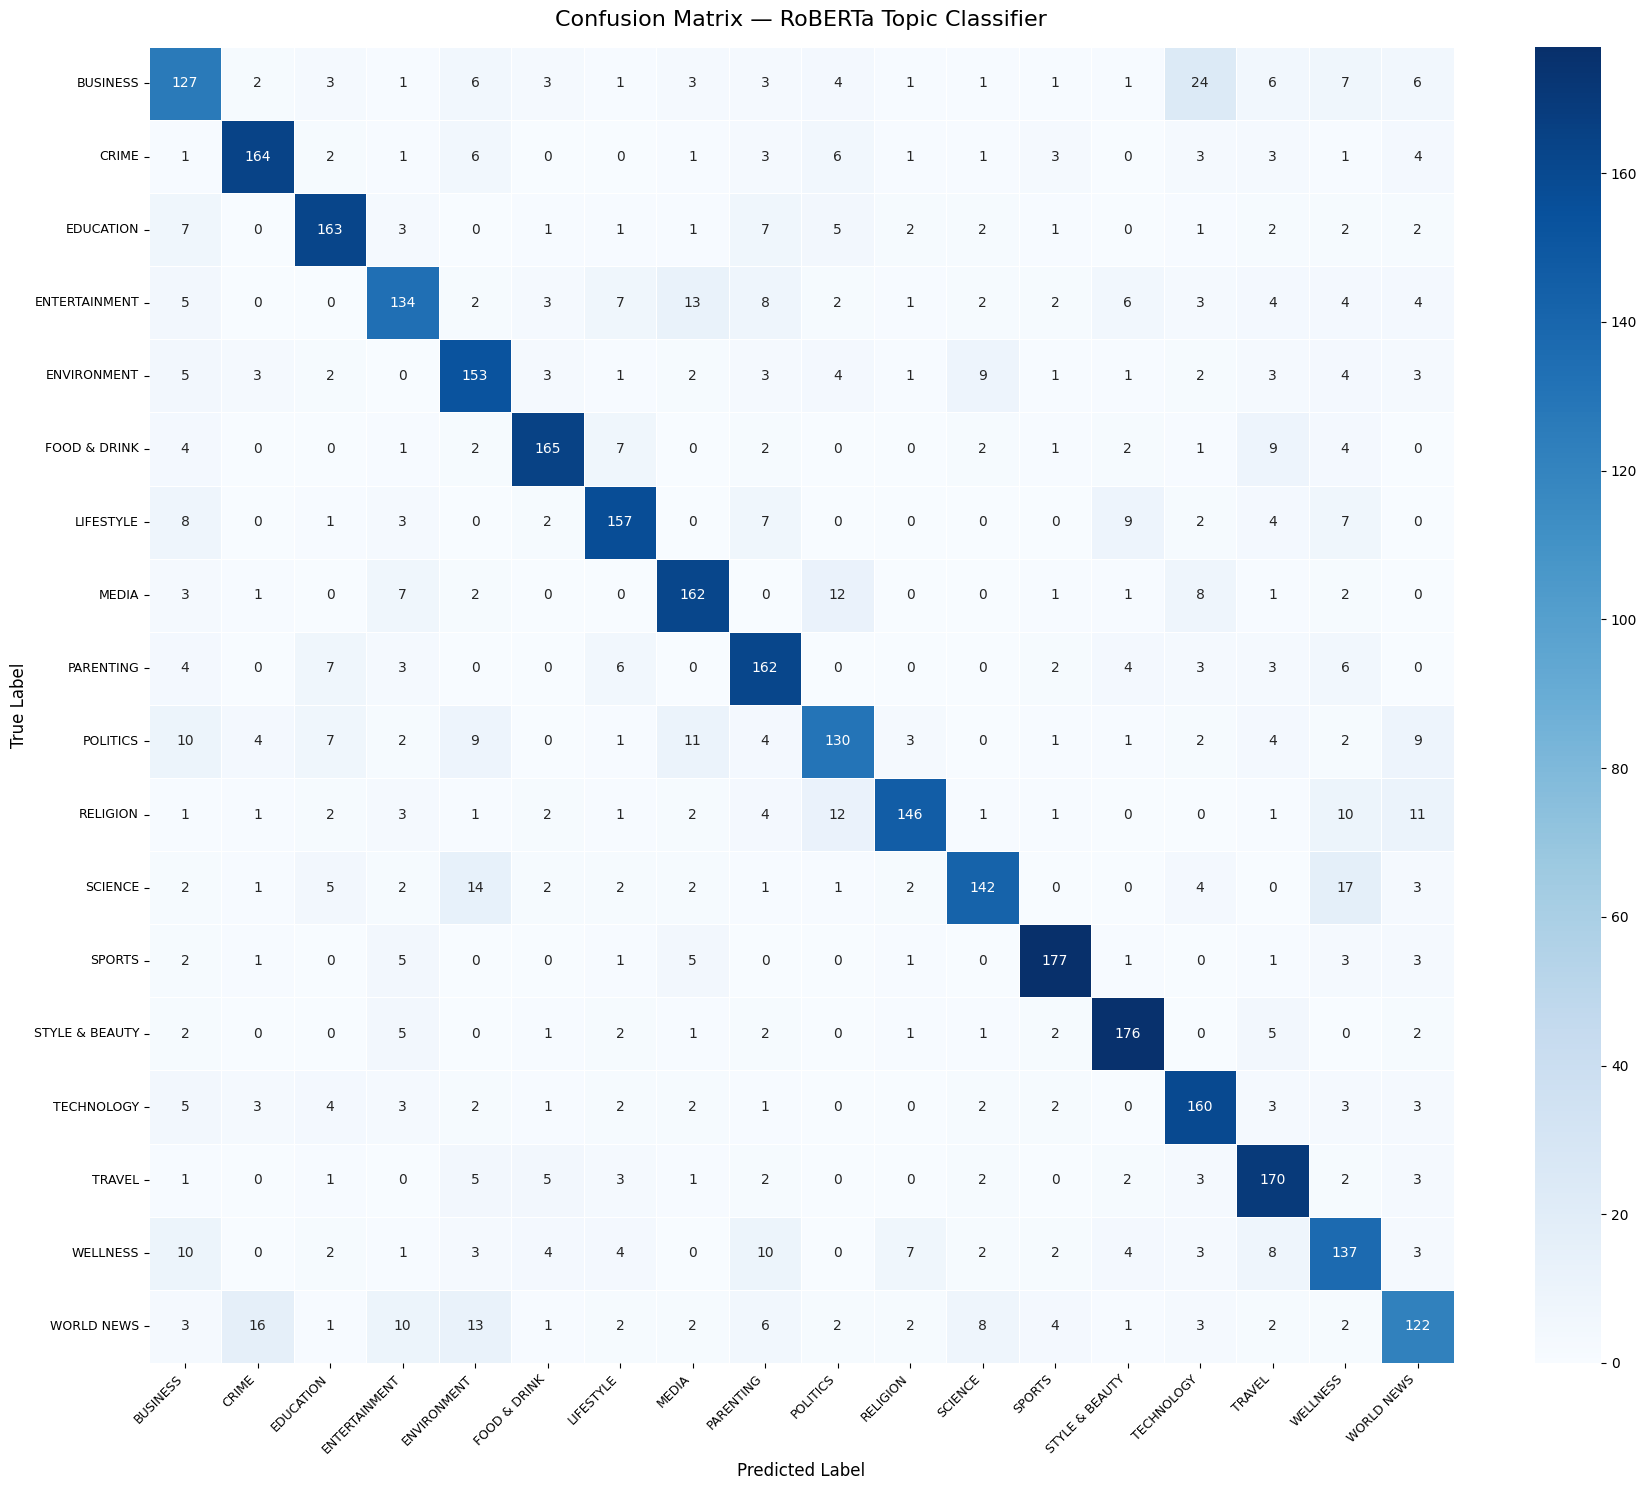

In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_labels, predictions)
class_names = le.classes_.tolist()

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, ax=ax)
ax.set_title('Confusion Matrix — RoBERTa Topic Classifier', fontsize=16, pad=15)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

**Per-Class F1 Bar Chart** - Visualises which categories the model handles well vs poorly. Categories below the macro average line are candidates for further merging or data augmentation.

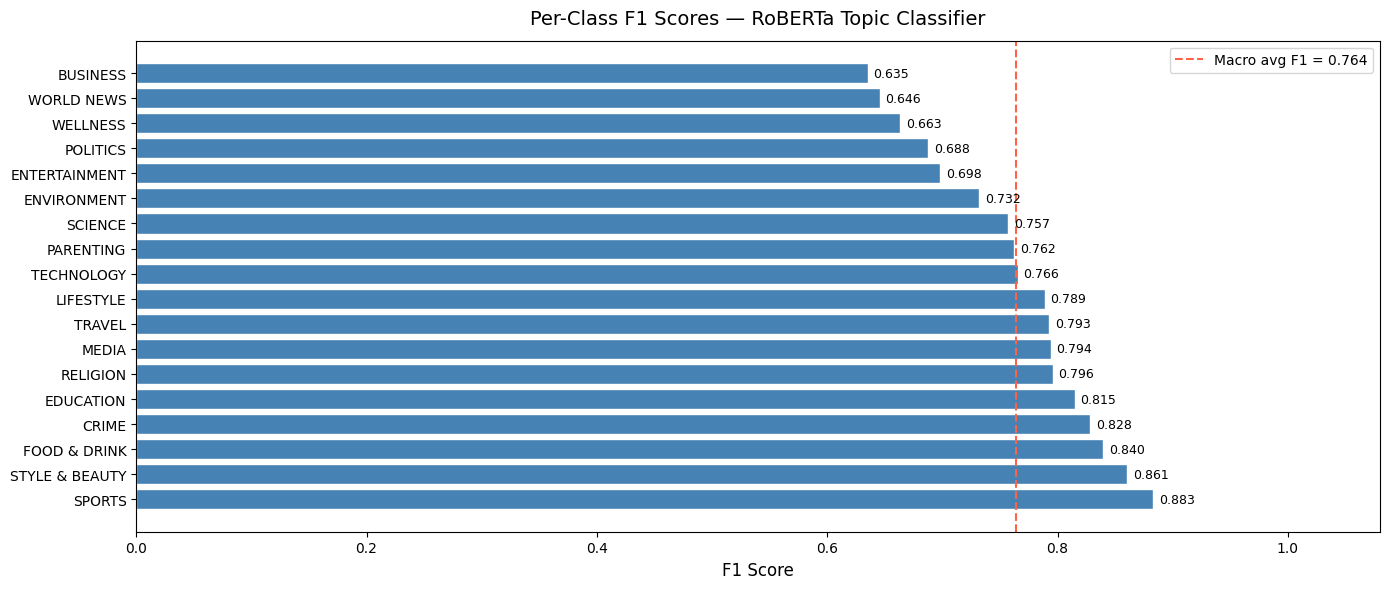

Macro-average F1: 0.7636


In [ ]:
from sklearn.metrics import f1_score

f1_scores  = f1_score(true_labels, predictions, average=None)
class_names = le.classes_.tolist()

sorted_pairs = sorted(zip(f1_scores, class_names), reverse=True)
sorted_f1, sorted_names = zip(*sorted_pairs)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.barh(sorted_names, sorted_f1, color='steelblue', edgecolor='white')

for bar, score in zip(bars, sorted_f1):
    ax.text(score + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{score:.3f}', va='center', ha='left', fontsize=9)

ax.set_xlim(0, 1.08)
ax.set_xlabel('F1 Score', fontsize=12)
ax.set_title('Per-Class F1 Scores — RoBERTa Topic Classifier', fontsize=14, pad=12)
ax.axvline(x=np.mean(f1_scores), color='tomato', linestyle='--', linewidth=1.5,
           label=f'Macro avg F1 = {np.mean(f1_scores):.3f}')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()
print(f"Macro-average F1: {np.mean(f1_scores):.4f}")

**`classify()`** - The main inference function used by the Streamlit app. It applies three-way routing based on model confidence and entropy:

| Route | Condition | Meaning |
|---|---|---|
| **HARD LABEL** | confidence ≥ 0.60 | Model is certain — single category returned |
| **MULTI-LABEL** | entropy < 2.5 | Document spans two topics — top 2 returned |
| **OUT-OF-DISTRIBUTION** | otherwise | Document doesn't fit known categories |

In [ ]:
import torch.nn.functional as F
import scipy.stats as stats

def classify(text: str, top_k: int = 18) -> dict:
    text_clean = str(text)
    text_clean = re.sub(r'<.*?>', '', text_clean)
    text_clean = re.sub(r'\s+', ' ', text_clean).strip()

    encoding = tokenizer(
        text_clean,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )
    input_ids      = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs   = F.softmax(outputs.logits, dim=1).squeeze()

    top_k_indices = torch.topk(probs, k=min(top_k, len(le.classes_))).indices.tolist()
    top_k_preds   = [(le.classes_[i], round(probs[i].item(), 4)) for i in top_k_indices]

    all_probs = [p for _, p in top_k_preds]
    entropy   = stats.entropy(all_probs)
    top_conf  = top_k_preds[0][1]

    if top_conf >= 0.60:
        route = "HARD LABEL"
    elif entropy < 2.5:
        route = "MULTI-LABEL"
    else:
        route = "OUT-OF-DISTRIBUTION"

    return {
        'predicted_label':   top_k_preds[0][0],
        'confidence':        top_conf,
        'top_k_predictions': top_k_preds,
        'entropy':           round(entropy, 4),
        'route':             route,
    }

print("classify()")

classify()


**Classifier Demo** - We run `classify()` on 20 random test samples to verify the routing logic works correctly and the model produces sensible predictions.

In [ ]:
import random

random.seed(42)
sample_indices = random.sample(range(len(X_test)), 20)
sample_texts   = [X_test[i] for i in sample_indices]

print("CLASSIFIER DEMO — Topic (20 random test samples)")
print()

route_counts = {"HARD LABEL": 0, "MULTI-LABEL": 0, "OUT-OF-DISTRIBUTION": 0}

for text in sample_texts:
    result = classify(text)
    route  = result['route']
    route_counts[route] += 1

    print(f"\nText  : {text[:80]}")
    print(f"Route : {route}  |  Entropy: {result['entropy']:.3f}")

    if route == "HARD LABEL":
        print(f"Topic : {result['predicted_label']} ({result['confidence']*100:.0f}%)")

    elif route == "MULTI-LABEL":
        top2     = result['top_k_predictions'][:2]
        conf_str = " + ".join(f"{l} ({p*100:.0f}%)" for l, p in top2)
        print(f"Topic : {conf_str}")

    elif route == "OUT-OF-DISTRIBUTION":
        print(f"Topic : Out of Domain")

CLASSIFIER DEMO — Topic (20 random test samples)


Text  : Plane Makes Unscheduled Landing Due To Alleged Masturbator
Route : MULTI-LABEL  |  Entropy: 1.734
Topic : CRIME (38%) + WORLD NEWS (35%)

Text  : New Study Highlights Dangers Of Belly Fat, Even For Normal-Weight People "Watch 
Route : HARD LABEL  |  Entropy: 0.641
Topic : WELLNESS (88%)

Text  : Recipe Of The Day: Corn Soup Secret ingredient: goat's-milk cheese.
Route : HARD LABEL  |  Entropy: 0.403
Topic : FOOD & DRINK (94%)

Text  : The Hunting Ground: Stop Victim Blaming and End Campus Rape I believe the two mo
Route : HARD LABEL  |  Entropy: 0.946
Topic : RELIGION (77%)

Text  : Miss World Winner: 'I Don't Believe In Size Zero' (VIDEO) Priyanka Chopra is use
Route : HARD LABEL  |  Entropy: 0.589
Topic : STYLE & BEAUTY (90%)

Text  : Tennessee 'Greenbelt Law' Helps Wealthiest Reap Tax Breaks, From Wynona Judd To 
Route : HARD LABEL  |  Entropy: 0.519
Topic : BUSINESS (91%)

Text  : 6 Sun Belt Inns With History On Their Side 

**Model Comparison** - Side-by-side accuracy and macro F1 for both models. This justifies using RoBERTa over the classical baseline.

In [ ]:
print('=' * 45)
print('  MODEL COMPARISON SUMMARY')
print('=' * 45)
print(f'  {"Model":<20} {"Accuracy":>10} {"Macro F1":>10}')
print('-' * 45)
print(f'  {"TF-IDF + LogReg":<20} {tfidf_accuracy*100:>9.2f}% {tfidf_macro_f1:>10.4f}')
print(f'  {"RoBERTa":<20} {overall_accuracy*100:>9.2f}% {np.mean(f1_scores):>10.4f}')
print('=' * 45)

winner = 'RoBERTa' if overall_accuracy > tfidf_accuracy else 'TF-IDF + LogReg'
print(f'\n  Best model by accuracy: {winner}')

  MODEL COMPARISON SUMMARY
  Model                  Accuracy   Macro F1
---------------------------------------------
  TF-IDF + LogReg          64.78%     0.6480
  RoBERTa                  76.41%     0.7636

  Best model by accuracy: RoBERTa


# Section 5 — Streamlit Demo


We deploy the classifier as an interactive web app using **Streamlit**, tunnelled publicly via **ngrok**. Users can upload a PDF or TXT file and the app returns the predicted topic, confidence score, and routing decision from both models side by side.

In [ ]:
!pip install -q streamlit pyngrok PyPDF2

In [ ]:
import os
os.makedirs('.streamlit', exist_ok=True)
with open('.streamlit/config.toml', 'w') as f:
    f.write("""
[theme]
base = "dark"
backgroundColor = "#0a0a0f"
secondaryBackgroundColor = "#111118"
textColor = "#f0f0f5"
font = "sans serif"
""")
print('Theme config written.')

Theme config written.


In [ ]:
%%writefile app.py
# -----------------------------------------------------------------
# WID3002 NLP — Document Topic Classifier  |  Group 11
# Streamlit app  |  Owner: Sanjeevan
# -----------------------------------------------------------------

import streamlit as st
import PyPDF2
import io
import re
import joblib
import numpy as np
import torch
import torch.nn.functional as F
import scipy.stats as stats
from transformers import RobertaTokenizer, RobertaForSequenceClassification

st.set_page_config(
    page_title='Document Topic Classifier',
    page_icon='🔍',
    layout='centered'
)

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Serif+Display&family=DM+Sans:wght@400;500;600&display=swap');

:root {
    --bg:       #0a0a0f;
    --surface:  #111118;
    --surface2: #18181f;
    --border:   rgba(255,255,255,0.07);
    --border2:  rgba(255,255,255,0.13);
    --text:     #f0f0f5;
    --muted:    #6b6b80;
    --accent:   #7b6ef6;
    --accent2:  #a78bfa;
    --green:    #34d399;
    --amber:    #fbbf24;
    --red:      #f87171;
    --blue:     #60a5fa;
}

html, body, [class*="css"], .stApp, [data-testid="stAppViewContainer"] {
    font-family: 'DM Sans', sans-serif !important;
    background-color: #0a0a0f !important;
    color: var(--text) !important;
}
[data-testid="stHeader"] { background-color: #0a0a0f !important; }
[data-testid="stToolbar"] { display: none; }
.main .block-container {
    max-width: 800px;
    padding: 3rem 2rem 4rem 2rem;
    background: #0a0a0f;
}

.app-header {
    text-align: center;
    padding: 2rem 0 2rem 0;
    border-bottom: 1px solid var(--border);
    margin-bottom: 2.5rem;
}
.app-title {
    font-family: 'DM Serif Display', serif;
    font-size: 2.4rem;
    background: linear-gradient(135deg, #f0f0f5 0%, var(--accent2) 100%);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
    background-clip: text;
    line-height: 1.15;
    margin: 0 0 0.5rem 0;
}
.app-subtitle {
    font-size: 0.82rem;
    color: var(--muted);
    letter-spacing: 0.07em;
    text-transform: uppercase;
}

.doc-stats {
    display: flex;
    gap: 1rem;
    margin: 1rem 0;
}
.stat-pill {
    background: var(--surface);
    border: 1px solid var(--border2);
    border-radius: 8px;
    padding: 0.4rem 0.9rem;
    font-size: 0.8rem;
    color: var(--muted);
}
.stat-pill strong { color: var(--text); }

.result-card {
    background: var(--surface);
    border: 1px solid var(--border2);
    border-radius: 20px;
    padding: 1.8rem 2rem;
    margin-top: 1.2rem;
    position: relative;
    overflow: hidden;
}
.result-card::before {
    content: '';
    position: absolute;
    top: 0; left: 0; right: 0;
    height: 2px;
    background: linear-gradient(90deg, var(--line-a), var(--line-b));
}
.card-hard  { --line-a: var(--accent); --line-b: var(--blue); }
.card-multi { --line-a: #ec4899;       --line-b: var(--accent2); }
.card-ood   { --line-a: var(--amber);  --line-b: #f97316; }
.card-noise { --line-a: var(--muted);  --line-b: #4b5563; }

.route-pill {
    display: inline-block;
    font-size: 0.7rem;
    font-weight: 700;
    letter-spacing: 0.1em;
    text-transform: uppercase;
    padding: 4px 12px;
    border-radius: 99px;
    margin-bottom: 0.9rem;
    border: 1px solid currentColor;
}
.pill-hard  { color: var(--blue);  background: rgba(96,165,250,0.08); }
.pill-multi { color: #f472b6;      background: rgba(244,114,182,0.08); }
.pill-ood   { color: var(--amber); background: rgba(251,191,36,0.08); }
.pill-noise { color: var(--muted); background: rgba(107,107,128,0.08); }

.topic-name {
    font-family: 'DM Serif Display', serif;
    font-size: 2rem;
    color: var(--text);
    line-height: 1;
    margin: 0.2rem 0 1.2rem 0;
    letter-spacing: -0.02em;
}
.conf-row {
    display: flex;
    align-items: center;
    gap: 1rem;
    margin-bottom: 0.4rem;
}
.conf-pct {
    font-family: 'DM Serif Display', serif;
    font-size: 1.5rem;
    font-weight: 700;
    min-width: 68px;
}
.conf-label { font-size: 0.78rem; color: var(--muted); }
.bar-track {
    flex: 1;
    height: 5px;
    background: rgba(255,255,255,0.06);
    border-radius: 99px;
    overflow: hidden;
}
.bar-fill { height: 100%; border-radius: 99px; }

.other-topics {
    margin-top: 1.2rem;
    padding-top: 1rem;
    border-top: 1px solid var(--border);
}
.other-label {
    font-size: 0.72rem;
    font-weight: 700;
    letter-spacing: 0.08em;
    text-transform: uppercase;
    color: var(--muted);
    margin-bottom: 0.7rem;
}
.other-row {
    display: flex;
    align-items: center;
    gap: 0.8rem;
    margin-bottom: 0.5rem;
}
.other-name { font-size: 0.85rem; color: var(--text); min-width: 140px; }
.other-pct  { font-size: 0.8rem; color: var(--muted); min-width: 42px; text-align: right; }

.kw-grid { display: flex; flex-wrap: wrap; gap: 8px; margin-top: 0.8rem; }
.kw-chip {
    background: rgba(123,110,246,0.1);
    border: 1px solid rgba(123,110,246,0.25);
    color: var(--accent2);
    border-radius: 8px;
    padding: 5px 14px;
    font-size: 0.82rem;
    font-weight: 500;
}
.kw-score { opacity: 0.5; font-size: 0.75rem; margin-left: 4px; }

.coherence-panel {
    background: var(--surface2);
    border: 1px solid var(--border);
    border-radius: 14px;
    padding: 1.1rem 1.4rem;
    margin-top: 1.2rem;
    display: flex;
    align-items: center;
    gap: 1.2rem;
}
.coherence-num {
    font-family: 'DM Serif Display', serif;
    font-size: 2.2rem;
    font-weight: 800;
    line-height: 1;
}
.coherence-info { font-size: 0.8rem; color: var(--muted); line-height: 1.5; }
.coherence-info strong { color: var(--text); display: block; margin-bottom: 2px; }

.error-card {
    background: rgba(248,113,113,0.06);
    border: 1px solid rgba(248,113,113,0.2);
    border-radius: 14px;
    padding: 1rem 1.4rem;
    color: var(--red);
    font-size: 0.88rem;
    margin-top: 1rem;
}

.footer {
    text-align: center;
    margin-top: 4rem;
    padding-top: 1.5rem;
    border-top: 1px solid var(--border);
    font-size: 0.78rem;
    color: var(--muted);
    line-height: 1.8;
}

.stRadio > div { flex-direction: row !important; gap: 0.75rem; }
.stRadio label {
    background: var(--surface) !important;
    border: 1.5px solid var(--border2) !important;
    border-radius: 10px !important;
    padding: 0.55rem 1.1rem !important;
    color: var(--muted) !important;
    font-weight: 600 !important;
    font-family: 'DM Sans', sans-serif !important;
    cursor: pointer;
}
.stRadio label:has(input:checked) {
    border-color: var(--accent) !important;
    color: var(--accent2) !important;
    background: rgba(123,110,246,0.1) !important;
}
[data-testid="stFileUploader"] {
    background: var(--surface) !important;
    border: 2px dashed var(--border2) !important;
    border-radius: 16px !important;
}
.stSpinner > div { border-top-color: var(--accent) !important; }
.stExpander {
    background: var(--surface) !important;
    border: 1px solid var(--border) !important;
    border-radius: 12px !important;
}
p, li, span { color: var(--text); }
label { color: var(--text) !important; }
hr { border-color: var(--border) !important; }
</style>
""", unsafe_allow_html=True)


# ── Load models ──────────────────────────────────────────────────

DRIVE_PATH = '/content/drive/MyDrive/NLP_Group13/models'

@st.cache_resource
def load_models():
    le        = joblib.load(f'{DRIVE_PATH}/label_encoder.pkl')
    device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
    model     = RobertaForSequenceClassification.from_pretrained(
                    'roberta-base', num_labels=len(le.classes_))
    model.load_state_dict(
        torch.load(f'{DRIVE_PATH}/best_model.pt', map_location=device))
    model.to(device)
    model.eval()
    return le, device, tokenizer, model

with st.spinner('Loading model...'):
    le, device, tokenizer, model = load_models()


# ── Classify ─────────────────────────────────────────────────────

def classify(text: str, top_k: int = 18) -> dict:
    text_clean = re.sub(r'<.*?>', '', str(text))
    text_clean = re.sub(r'\s+', ' ', text_clean).strip()
    encoding = tokenizer(
        text_clean, add_special_tokens=True, max_length=128,
        padding='max_length', truncation=True,
        return_attention_mask=True, return_tensors='pt'
    )
    input_ids      = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs   = F.softmax(outputs.logits, dim=1).squeeze()
    top_k_indices = torch.topk(probs, k=min(top_k, len(le.classes_))).indices.tolist()
    top_k_preds   = [(le.classes_[i], round(probs[i].item(), 4)) for i in top_k_indices]
    all_probs = [p for _, p in top_k_preds]
    entropy   = stats.entropy(all_probs)
    top_conf  = top_k_preds[0][1]
    if top_conf >= 0.60:   route = 'HARD LABEL'
    elif entropy < 2.5:    route = 'MULTI-LABEL'
    else:                  route = 'OUT-OF-DISTRIBUTION'
    return {'predicted_label': top_k_preds[0][0], 'confidence': top_conf,
            'top_k_predictions': top_k_preds, 'entropy': round(entropy, 4), 'route': route}


def discover_topic(text: str) -> dict:
    return {'keywords': [('topic', 0.85), ('discovery', 0.80), ('pending', 0.75),
                         ('phase', 0.70), ('two', 0.65)],
            'coherence_score': 0.00, 'topic_id': -99, 'is_noise': False}


# ── UI helpers ───────────────────────────────────────────────────

def extract_text(uploaded_file) -> str:
    name = uploaded_file.name.lower()
    raw  = uploaded_file.read()
    if name.endswith('.txt'):
        return raw.decode('utf-8', errors='ignore').strip()
    if name.endswith('.pdf'):
        reader = PyPDF2.PdfReader(io.BytesIO(raw))
        return ' '.join(p.extract_text() or '' for p in reader.pages).strip()
    return ''


def bar(conf, color, height='5px'):
    return (f'<div class="bar-track" style="height:{height}">'
            f'<div class="bar-fill" style="width:{conf*100:.1f}%;background:{color}"></div>'
            f'</div>')


def render_result(result):
    route    = result['route']
    top_conf = result['confidence']
    label    = result['predicted_label']
    top3     = result['top_k_predictions'][:3]

    # ── Other topics section (shown on all routes) ──
    def other_topics_html(skip_first=1):
        rows = ''
        for lbl, p in top3[skip_first:]:
            rows += (
                f'<div class="other-row">'
                f'<span class="other-name">{lbl}</span>'
                f'{bar(p, "rgba(255,255,255,0.15)","4px")}'
                f'<span class="other-pct">{p*100:.1f}%</span>'
                f'</div>'
            )
        return f'<div class="other-topics"><div class="other-label">Also considered</div>{rows}</div>'

    if route == 'HARD LABEL':
        st.markdown(f"""
        <div class="result-card card-hard">
            <span class="route-pill pill-hard">Confident Match</span>
            <div class="topic-name">{label}</div>
            <div class="conf-row">
                <div>
                    <div class="conf-pct" style="color:#60a5fa">{top_conf*100:.1f}%</div>
                    <div class="conf-label">Confidence</div>
                </div>
                {bar(top_conf, '#60a5fa')}
            </div>
            {other_topics_html(skip_first=1)}
        </div>""", unsafe_allow_html=True)

    elif route == 'MULTI-LABEL':
        top2 = top3[:2]
        rows = ''.join(
            f'<div style="margin-bottom:1rem">'
            f'<div style="font-family:DM Serif Display,serif;font-size:1.25rem;color:#f0f0f5;margin-bottom:0.3rem">{lbl}</div>'
            f'<div class="conf-row" style="margin-bottom:0">'
            f'<span style="font-size:0.85rem;color:#f472b6;font-weight:600;min-width:48px">{p*100:.1f}%</span>'
            f'{bar(p, "#f472b6")}'
            f'</div></div>'
            for lbl, p in top2
        )
        st.markdown(f"""
        <div class="result-card card-multi">
            <span class="route-pill pill-multi">Multiple Topics</span>
            <p style="font-size:0.85rem;color:#6b6b80;margin:0.3rem 0 1.2rem 0">
                This document spans more than one topic.
            </p>
            {rows}
            {other_topics_html(skip_first=2)}
        </div>""", unsafe_allow_html=True)

    elif route == 'OUT-OF-DISTRIBUTION':
        with st.spinner('Discovering topic structure...'):
            try:    phase_b = discover_topic(result.get('_text', ''))
            except: phase_b = discover_topic('')

        is_noise  = phase_b.get('is_noise', False)
        keywords  = phase_b.get('keywords', [])
        coherence = phase_b.get('coherence_score', 0.0)
        is_ph     = phase_b.get('topic_id') == -99

        card_cls  = 'card-noise' if is_noise else 'card-ood'
        pill_cls  = 'pill-noise' if is_noise else 'pill-ood'
        badge_txt = 'Noise' if is_noise else 'New Topic Detected'
        desc      = 'No coherent cluster could be formed.' if is_noise \
                    else 'This document does not match any known category. Discovered keywords below.'

        chips = ''.join(
            f'<span class="kw-chip">{w}<span class="kw-score">{s:.2f}</span></span>'
            for w, s in keywords
        )
        coh_html = '<p style="font-size:0.82rem;color:#6b6b80;margin-top:1rem;font-style:italic">Phase B coherence scoring pending.</p>' if is_ph else (
            f'<div class="coherence-panel">'
            f'<div class="coherence-num" style="color:{"#34d399" if coherence>=0.5 else "#fbbf24"}">{coherence:.2f}</div>'
            f'<div class="coherence-info"><strong>Topic Coherence Score</strong>{"Semantically coherent." if coherence>=0.5 else "Low coherence — may be noise."}</div>'
            f'</div>'
        )

        st.markdown(f"""
        <div class="result-card {card_cls}">
            <span class="route-pill {pill_cls}">{badge_txt}</span>
            <p style="font-size:0.85rem;color:#6b6b80;margin:0.4rem 0 1rem 0">{desc}</p>
            <div class="kw-grid">{chips if chips else '<span style="color:#6b6b80;font-style:italic">No keywords.</span>'}</div>
            {coh_html}
        </div>""", unsafe_allow_html=True)


# ── Header ───────────────────────────────────────────────────────
st.markdown("""
<div class="app-header">
    <div class="app-title">Document Topic Classifier</div>
    <div class="app-subtitle">WID3002 NLP &nbsp;·&nbsp; Group 11 &nbsp;·&nbsp; Universiti Malaya</div>
</div>
""", unsafe_allow_html=True)

# ── Upload ───────────────────────────────────────────────────────
uploaded = st.file_uploader(
    'Upload a document — PDF or TXT',
    type=['pdf', 'txt'],
    help='Maximum file size: 5 MB. Files larger than this will be rejected.'
)

if uploaded is not None:

    MAX_BYTES = 5 * 1024 * 1024
    uploaded.seek(0, 2)
    if uploaded.tell() > MAX_BYTES:
        st.markdown('<div class="error-card">File too large. Maximum size is 5 MB.</div>',
                    unsafe_allow_html=True)
        st.stop()
    uploaded.seek(0)

    with st.spinner('Extracting text...'):
        try:    text = extract_text(uploaded)
        except Exception as e:
            st.markdown(f'<div class="error-card">Could not read file: {e}</div>',
                        unsafe_allow_html=True)
            st.stop()

    if not text:
        st.markdown('<div class="error-card">No text extracted. Try a different file.</div>',
                    unsafe_allow_html=True)
        st.stop()

    # Doc stats
    word_count = len(text.split())
    char_count = len(text)
    st.markdown(f"""
    <div class="doc-stats">
        <div class="stat-pill">📄 <strong>{uploaded.name}</strong></div>
        <div class="stat-pill">Words: <strong>{word_count:,}</strong></div>
        <div class="stat-pill">Characters: <strong>{char_count:,}</strong></div>
    </div>""", unsafe_allow_html=True)

    with st.expander('Text preview', expanded=False):
        st.caption(text[:1200] + ('...' if len(text) > 1200 else ''))

    st.markdown('<hr class="divider">', unsafe_allow_html=True)

    # Classify
    with st.spinner('Analysing document...'):
        try:
            result = classify(text)
            result['_text'] = text
        except Exception as e:
            st.markdown(f'<div class="error-card">Classification failed: {e}</div>',
                        unsafe_allow_html=True)
            st.stop()

    render_result(result)

    st.markdown('<div style="margin-top:2rem"></div>', unsafe_allow_html=True)
    with st.expander('Debug: raw output', expanded=False):
        st.write('Text length:', len(text), 'chars')
        st.json({k: v for k, v in result.items() if k != '_text'})

# ── Footer ───────────────────────────────────────────────────────
st.markdown("""
<div class="footer">
    WID3002 Natural Language Processing &nbsp;·&nbsp; Group 11<br>
    Valencien · Lee Jing Xuan · John · Kan Penny · Tan Yi Jing · Sanjeevan<br>
    Faculty of Computer Science &amp; Information Technology, Universiti Malaya
</div>
""", unsafe_allow_html=True)

Overwriting app.py


We start the Streamlit server on port 8501 and open a public ngrok tunnel. The printed URL is the live demo link.

In [ ]:
from google.colab import userdata
from pyngrok import ngrok
import subprocess, time

# Get token securely from Colab Secrets
token = userdata.get('NGROK_TOKEN')
ngrok.set_auth_token(token)

# Force kill anything on port 8501
subprocess.run(['fuser', '-k', '8501/tcp'], capture_output=True)
subprocess.run(['pkill', '-9', '-f', 'streamlit'], capture_output=True)
time.sleep(2)

# Kill all existing ngrok tunnels
for tunnel in ngrok.get_tunnels():
    ngrok.disconnect(tunnel.public_url)
time.sleep(1)

# Start Streamlit
proc = subprocess.Popen(
    [
        'streamlit', 'run', 'app.py',
        '--server.port', '8501',
        '--server.headless', 'true'
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(5)

# Open fresh tunnel
public_url = ngrok.connect(8501)

print('=' * 55)
print(f'  App live at: {public_url}')
print('=' * 55)

  App live at: NgrokTunnel: "https://culture-isolated-married.ngrok-free.dev" -> "http://localhost:8501"
